In [5]:
from google.colab import files
uploaded = files.upload()

Saving ab_data.csv to ab_data.csv


In [6]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Loading the data
df = pd.read_csv('ab_data.csv')

# 2. Data validation and cleaning
valid_mask = ((df['group'] == 'control') & (df['landing_page'] == 'old_page')) | \
             ((df['group'] == 'treatment') & (df['landing_page'] == 'new_page'))

df_clean = df[valid_mask].copy()
misassigned_count = len(df) - len(df_clean)
print(f"Number of misassigned rows removed: {misassigned_count}")
print(f"Number of rows remaining in clean dataset: {len(df_clean)}")

Number of misassigned rows removed: 3893
Number of rows remaining in clean dataset: 290585


In [7]:
# Summary table by groups
summary = df_clean.groupby('group').agg(
    total_users=('user_id', 'count'),
    conversions=('converted', 'sum')
).reset_index()

summary['conversion_rate'] = summary['conversions'] / summary['total_users']
print(summary)

# Calculating absolute and relative differences
control_cr = summary.loc[summary['group'] == 'control', 'conversion_rate'].values[0]
treatment_cr = summary.loc[summary['group'] == 'treatment', 'conversion_rate'].values[0]

abs_diff = treatment_cr - control_cr
rel_diff = (treatment_cr - control_cr) / control_cr

print("Control CR:", control_cr)
print("Treatment CR:", treatment_cr)
print("Absolute Diff:", abs_diff)
print("Relative Diff:", rel_diff)

       group  total_users  conversions  conversion_rate
0    control       145274        17489         0.120386
1  treatment       145311        17264         0.118807
Control CR: 0.1203863045004612
Treatment CR: 0.11880724790277405
Absolute Diff: -0.0015790565976871451
Relative Diff: -0.0131165800315857


Z-statistic: 1.3116075339133115
P-value: 0.18965258971881804


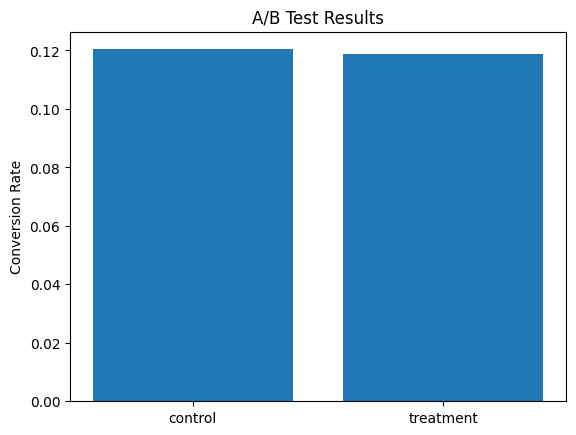

In [8]:
import statsmodels.api as sm

conversions = summary['conversions'].values
total_users = summary['total_users'].values

z_stat, p_value = sm.stats.proportions_ztest(conversions, total_users)

print("Z-statistic:", z_stat)
print("P-value:", p_value)

groups = summary['group']
rates = summary['conversion_rate']

plt.bar(groups, rates)
plt.ylabel('Conversion Rate')
plt.title('A/B Test Results')
plt.show()

          date      group  total_users  conversions  conversion_rate
0   2017-01-02    control         2859          359         0.125568
1   2017-01-02  treatment         2853          342         0.119874
2   2017-01-03    control         6590          750         0.113809
3   2017-01-03  treatment         6618          753         0.113781
4   2017-01-04    control         6578          802         0.121922
5   2017-01-04  treatment         6541          763         0.116649
6   2017-01-05    control         6427          792         0.123230
7   2017-01-05  treatment         6505          748         0.114988
8   2017-01-06    control         6606          762         0.115350
9   2017-01-06  treatment         6747          833         0.123462
10  2017-01-07    control         6604          799         0.120987
11  2017-01-07  treatment         6609          768         0.116205
12  2017-01-08    control         6687          795         0.118887
13  2017-01-08  treatment         

<Figure size 1000x800 with 0 Axes>

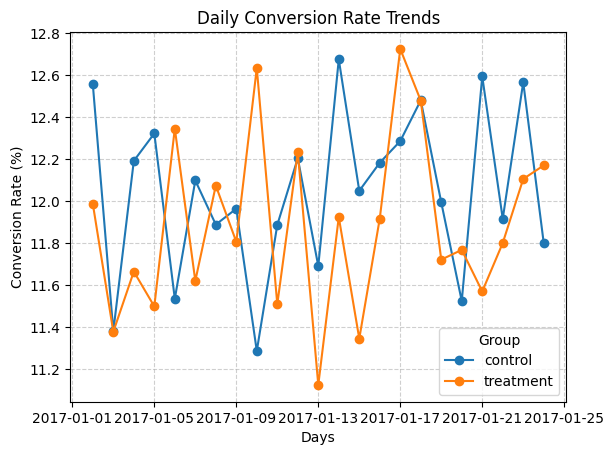

In [9]:
# daily conversion rate

df_clean['date'] = pd.to_datetime(df_clean['timestamp']).dt.date
monthly_summary = df_clean.groupby(['date', 'group']).agg(
    total_users=('user_id', 'count'),
    conversions=('converted', 'sum')
).reset_index()

monthly_summary['conversion_rate'] = monthly_summary['conversions'] / monthly_summary['total_users']
print(monthly_summary)

pivot_monthly = monthly_summary.pivot(index='date', columns='group', values='conversion_rate') * 100

plt.figure(figsize=(10, 8))
pivot_monthly.plot(marker='o')

plt.ylabel('Conversion Rate (%)')
plt.xlabel('Days')
plt.title('Daily Conversion Rate Trends')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Group')

plt.show()

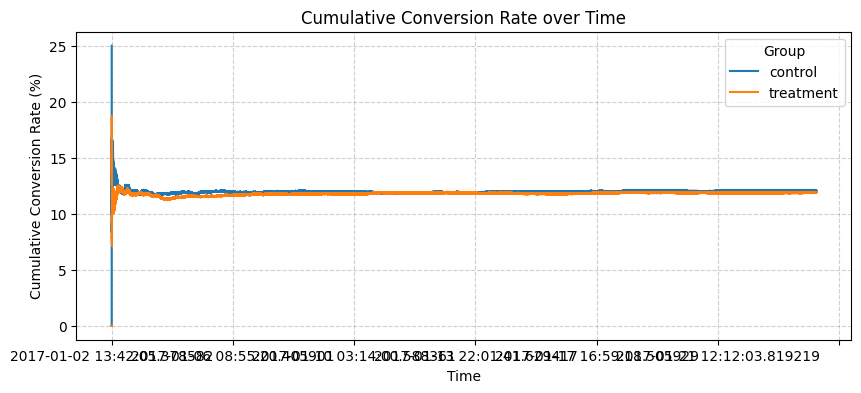

In [10]:
# cumulative conversion rate

df_sorted = df_clean.sort_values('timestamp')

df_sorted['cumulative_users'] = df_sorted.groupby('group')['user_id'].cumcount() + 1
df_sorted['cumulative_conversions'] = df_sorted.groupby('group')['converted'].cumsum()

df_sorted['cumulative_cr'] = df_sorted['cumulative_conversions'] / df_sorted['cumulative_users']

pivot_cumulative = df_sorted.pivot_table(index='timestamp', columns='group', values='cumulative_cr') * 100

plt.figure(figsize=(10, 4))
pivot_cumulative.plot(ax=plt.gca())

plt.ylabel('Cumulative Conversion Rate (%)')
plt.xlabel('Time')
plt.title('Cumulative Conversion Rate over Time')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(title='Group')

plt.show()